In [1]:
"""This file is to test dedicated algorithms
"""

import config as cfg
from data_acquirer import get_data, gen_data
from data_processor import process
import helpers
import heuristic
from heuristic import Path, VGeneralizedSolver
from solver import solve_pdpcr


import pickle
import copy
import datetime
from docplex.mp.model import Model
import logging
import heapq
import networkx as nx
import numpy as np
import random 
import time

logging.basicConfig(format=cfg.LOG_FORMATTER, level=cfg.LOG_LEVEL, datefmt='%d-%b-%y %H:%M:%S')

In [2]:
# Test dedicated insert functions

# Data from document "redistribute paper"
sol_graph = nx.DiGraph()
sol_graph.add_edge(0, 1, weight=5)
sol_graph.add_edge(0, 2, weight=2)
sol_graph.add_edge(1, 3, weight=1)
# sol_graph.add_edge(1, 4, weight=4)
sol_graph.add_edge(1, -1, weight=4)
sol_graph.add_edge(2, 3, weight=1)
sol_graph.add_edge(2, 5, weight=1)
sol_graph.add_edge(3, 5, weight=2)
# sol_graph.add_edge(4, -1, weight=4)
sol_graph.add_edge(5, -1, weight=3)

N_left = [0,1,2,3]
N_right = [5,-1]
l = {
    0:0,
    1:4,
    2:7,
    3:12,
    # 4:11,
    5:20,
    -1:24
}

l_bar ={
    0:0,
    1:9,
    2:9,
    3:16,
    # 4:14,
    5:22,
    -1:24
}

l_star = {
    0:24,
    1:18,
    2:17,
    3:12,
    # 4:5,
    5:4,
    -1:0
}

ls = (l,l_bar,l_star, None)

c_travel = {
    0:{
        1:4,
        2:7,
        4:66,
        5:88,
        -1:0
    },
    1:{
        4:6,
        5:4,
        -1:99
    },
    2:{
        4:2,
        5:3,
        -1:99
    },
    3:{
        4:1,
        5:4,
        -1:99
    },
    4:{
        4:99,
        -1:2,
        5:9
    },
}

c_operate = {
    0:0,
    1:1,
    2:2,
    3:4,
    4:3,
    5:1,
    -1:0
}

pi_left={
    0:0,
    1:4,
    2:1,
    3:2
}

pi_right = {
    # 4:4,
    5:3,
    -1:3
}

greedy = heuristic.GreedyInsert(None,c_travel,c_operate)

In [3]:
i_hat = 4
n_i_hat = 4
sol_graph, C_max = greedy._high_dedicated_insert(sol_graph, N_left, N_right,  pi_left, pi_right,ls,i_hat,n_i_hat)
print(C_max)

12-Nov-24 19:26:06:INFO:Current thetas: [14, 18, 20]
12-Nov-24 19:26:06:INFO:Current thetas: [14, 18]


22


In [12]:
sol_graph.edges(data=True)

OutEdgeDataView([(0, 1, {'weight': 5}), (0, 2, {'weight': 2}), (1, 3, {'weight': 1}), (1, 5, {'weight': 2}), (1, 4, {'weight': 2}), (2, 3, {'weight': 1}), (2, 5, {'weight': 1}), (3, 4, {'weight': 2}), (5, -1, {'weight': 3}), (4, -1, {'weight': 4})])

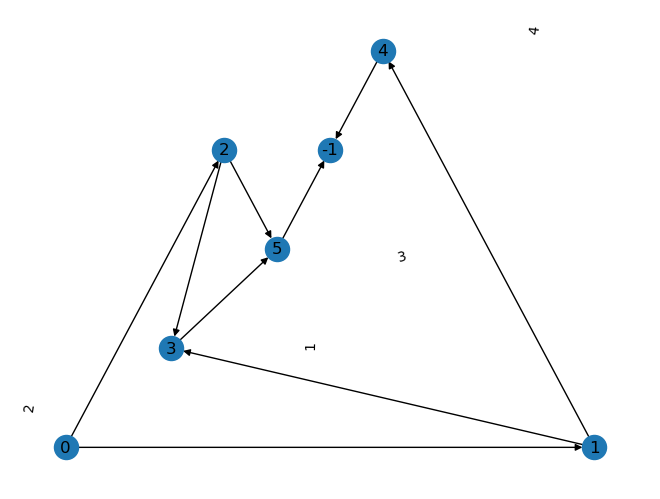

In [7]:
#Draw the graph
import matplotlib.pyplot as plt
pos = nx.spring_layout(sol_graph)
nx.draw_planar(sol_graph, with_labels=True)
labels = nx.get_edge_attributes(sol_graph, 'weight')
nx.draw_networkx_edge_labels(sol_graph, pos, edge_labels=labels)
plt.show()

In [9]:
topo_order  = list(nx.topological_sort(sol_graph))
greedy._get_related_times(sol_graph, greedy.c_travel, greedy.c_operate, topo_order)

KeyError: 0

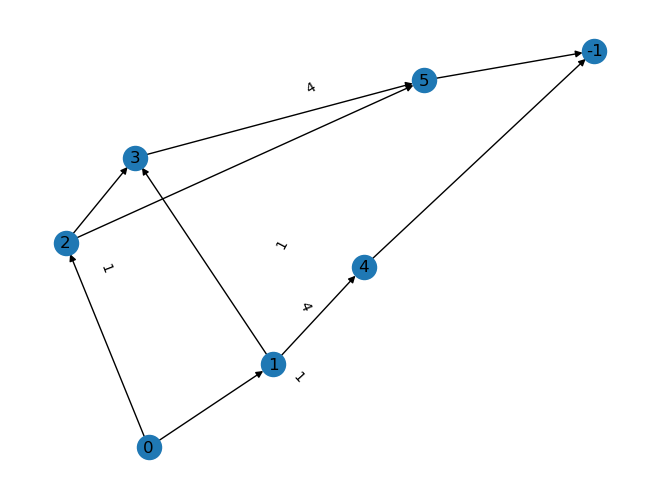

In [ ]:
#Draw the graph as a DAG
import matplotlib.pyplot as plt
pos = nx.spring_layout(sol_graph)
nx.draw(sol_graph, with_labels=True)
labels = nx.get_edge_attributes(sol_graph, 'weight')
nx.draw_networkx_edge_labels(sol_graph, pos, edge_labels=labels)
plt.show()


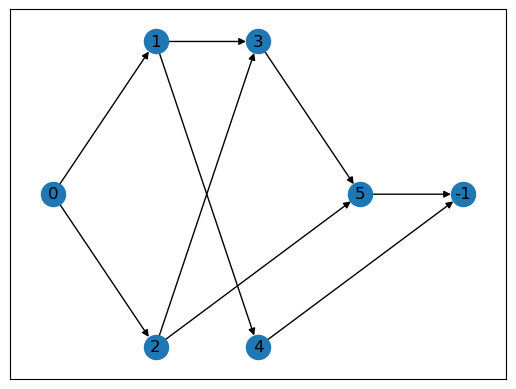

In [21]:
for layer, nodes in enumerate(nx.topological_generations(sol_graph)):
    # `multipartite_layout` expects the layer as a node attribute, so add the
    # numeric layer value as a node attribute
    for node in nodes:
        sol_graph.nodes[node]["layer"] = layer
pos = nx.multipartite_layout(sol_graph, subset_key="layer")
nx.draw_networkx(sol_graph, pos, with_labels=True)

In [2]:
# Test tabu dedicated redistribute functions

# Data from document "redistribute paper"
sol_graph = nx.DiGraph()
sol_graph.add_edge(0, 1, weight=5)
sol_graph.add_edge(0, 2, weight=2)
sol_graph.add_edge(1, 3, weight=1)
sol_graph.add_edge(1, 4, weight=4)
sol_graph.add_edge(2, 3, weight=1)
sol_graph.add_edge(2, 5, weight=1)
sol_graph.add_edge(3, 5, weight=2)
sol_graph.add_edge(4, -1, weight=4)
sol_graph.add_edge(5, -1, weight=3)

N_left = [0,1,2,3]
N_right = [4,5,-1]
l = {
    0:0,
    1:4,
    2:7,
    3:12,
    4:11,
    5:20,
    -1:24
}

l_bar ={
    0:0,
    1:9,
    2:9,
    3:16,
    4:14,
    5:22,
    -1:24
}

l_star = {
    0:24,
    1:18,
    2:17,
    3:12,
    4:5,
    5:4,
    -1:0
}

ls = (l,l_bar,l_star)

c_travel = {
    0:{
        1:4,
        2:7,
        4:66,
        5:88,
        -1:0
    },
    1:{
        4:6,
        5:4,
        -1:99
    },
    2:{
        4:2,
        5:3,
        -1:99
    },
    3:{
        4:1,
        5:4,
        -1:99
    }
}

c_operate = {
    0:0,
    1:1,
    2:2,
    3:4,
    4:3,
    5:1,
    -1:0
}

pi_left={
    0:0,
    1:4,
    2:1,
    3:2
}

pi_right = {
    4:4,
    5:3,
    -1:0
}

tabu = heuristic.TabuSearch(None,c_travel,c_operate)

In [3]:
tabu._dedicated_redistribute(sol_graph, N_left, N_right,pi_left, pi_right, ls)

In [11]:

total_robots = 10
random_data = False

data_type = 'csv'
data_name = 'data4.csv'
# data_name = 'generated2.csv'
# data_name = 'lim/100/lrc204-5-uniform.csv'
# data_name = 'lim/100/lr105-5-uniform.csv'
data_name = 'lim/200/LC1_2_4-5-uniform.csv'
total_tasks = 6 # random data

raw = get_data(data_name, data_type)
logging.info(f'Solving data {data_name} with {total_robots} robots and {len(raw.tasks)} tasks')
processed_h = heuristic.process_greedy_1(raw)

depot = processed_h.depot
tasks = processed_h.tasks
c_travel = helpers.create_task_dist_dict(depot,tasks)
c_operate = helpers.create_operate_dict(depot,tasks)

02-Dec-24 22:35:15:INFO:Solving data lim/200/LC1_2_4-5-uniform.csv with 10 robots and 105 tasks


In [17]:
cfg.GREEDY_DEBUG = True

cfg.DEDICATED_INSERT = False
greedy_v2 = heuristic.GreedyInsert(processed_h, c_travel, c_operate)
cplex_results = greedy_v2.solve(total_robots)

cfg.DEDICATED_INSERT = True
greedy_v2_dedi = heuristic.GreedyInsert(processed_h, c_travel, c_operate)
dedicated_results = greedy_v2_dedi.solve(total_robots)

_,_, cpl_fs,cpl_Cmaxs = cplex_results
_,_, dedi_fs, dedi_Cmaxs = dedicated_results

02-Dec-24 22:53:50:INFO:CPLEX insert
02-Dec-24 22:53:50:INFO:zeta_max: 2
02-Dec-24 22:53:50:INFO:zeta_max: 3
02-Dec-24 22:53:51:INFO:zeta_max: 4
02-Dec-24 22:53:51:INFO:zeta_max: 5
02-Dec-24 22:53:51:INFO:zeta_max: 6
02-Dec-24 22:53:51:INFO:zeta_max: 7
02-Dec-24 22:53:51:INFO:zeta_max: 8
02-Dec-24 22:53:51:INFO:zeta_max: 9
02-Dec-24 22:53:51:INFO:zeta_max: 10
02-Dec-24 22:53:51:INFO:zeta_max: 11
02-Dec-24 22:53:51:INFO:zeta_max: 12
02-Dec-24 22:53:52:INFO:zeta_max: 13
02-Dec-24 22:53:52:INFO:zeta_max: 14
02-Dec-24 22:53:52:INFO:zeta_max: 15
02-Dec-24 22:53:52:INFO:zeta_max: 16
02-Dec-24 22:53:53:INFO:zeta_max: 17
02-Dec-24 22:53:53:INFO:zeta_max: 18
02-Dec-24 22:53:53:INFO:zeta_max: 19
02-Dec-24 22:53:54:INFO:zeta_max: 20
02-Dec-24 22:53:54:INFO:zeta_max: 21
02-Dec-24 22:53:54:INFO:zeta_max: 22
02-Dec-24 22:53:55:INFO:zeta_max: 23
02-Dec-24 22:53:55:INFO:zeta_max: 24
02-Dec-24 22:53:56:INFO:zeta_max: 25
02-Dec-24 22:53:56:INFO:zeta_max: 26
02-Dec-24 22:53:57:INFO:zeta_max: 27
02-Dec-24

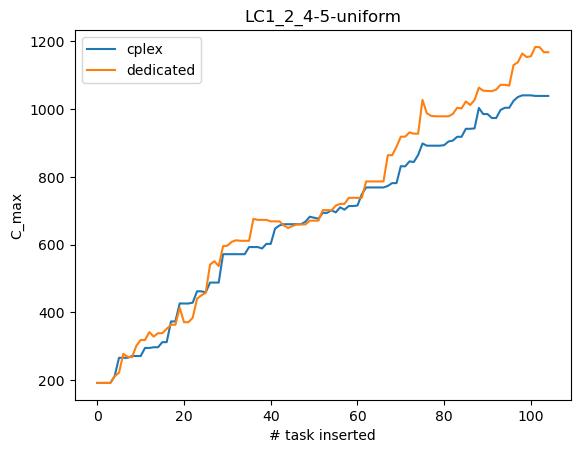

In [18]:
#plot cpl_Cmax, dedi_Cmax 
from matplotlib import pyplot as plt
data_name_to_save = data_name.split('/')[2].split('.')[0]
plt.plot(cpl_Cmaxs, label='cplex')
plt.plot(dedi_Cmaxs, label='dedicated')
plt.xlabel('# task inserted')
plt.ylabel('C_max')
plt.title(data_name_to_save)
plt.legend()
plt.savefig(f'cpl_vs_dedi-{data_name_to_save}.png')
plt.show()
# add axes label: x-axis is named "# task inserted", y-axis is named "Cmax"
# add title: "Cmax comparison between cplex and dedicated insert"



In [25]:
data_name.split('/')[2].split('.')[0]

'lc208-5-uniform'

In [5]:
sol_path = './solve_results/greedy2/lc208-5-uniform_2024-11-13_11-55-32'
sf = heuristic.SolutionFetcher(sol_path)
init_sol_graph = sf.fetch()
# greedy = heuristic.GreedyInsert(init_sol_graph, c_travel, c_operate)

In [6]:
topo_order = list(nx.topological_sort(init_sol_graph))
l,*_ = greedy_v2._get_related_times(init_sol_graph,c_travel,c_operate,topo_order)

In [ ]:
#Li larger data

first_names = ['LC1']
sec_names = [2,4,6,8,10]
third_names = [i for i in range(1,11)]
data_paths =[f'lim/{j}00/{i}_{j}_{k}-5-uniform.csv'for i in first_names for j in sec_names for k in third_names]#
num_robots = [10*i for i in range(1,4)]
method = 5
file_type = 'csv'
is_depot_task = False

In [19]:
#Li smaller data
small_first_names =['lc','lr','lrc']
small_sec_names = [100+i for i in range(1,10)] + [200 + i for i in range(1,10)]
data_paths = [f'lim/100/{i}{j}-5-uniform.csv' for i in small_first_names for j in small_sec_names]


In [21]:
cfg.GREEDY_DEBUG = False
cfg.DEDICATED_INSERT = True
num_robots = [10]
file_type = 'csv'
is_depot_task = False
logging.info(f'cfg.DEDICATED_INSERT: {cfg.DEDICATED_INSERT}')
logging.info(f'IHat not random: {cfg.DEBUG_IHAT_NOT_RANDOM}')
if cfg.DEDICATED_INSERT:
    solve_note = f'dedicated insert and i hat not random : {cfg.DEBUG_IHAT_NOT_RANDOM}'
else:
    solve_note = f'cplex insert and i hat not random : {cfg.DEBUG_IHAT_NOT_RANDOM}'
#new greedy search
for num_robot in num_robots:
    for data_path in data_paths:
        try:
            raw = get_data(data_path, file_type, is_depot_task)
            logging.info(f'Solving data {data_path} with {num_robot} robots and {len(raw.tasks)} tasks')
            # processed_data = process(raw, method)
            processed_h = heuristic.process_greedy_1(raw)
            depot = processed_h.depot
            tasks = processed_h.tasks
            c_travel = helpers.create_task_dist_dict(depot,tasks)
            c_operate = helpers.create_operate_dict(depot,tasks)

            tik1 = time.time()
            greedy_v2 = heuristic.GreedyInsert(processed_h, c_travel, c_operate)
            greedy_v2_F, greedy_v2_C_max, *rest = greedy_v2.solve(num_robot)
            tok1 = time.time()
            greedy_time = tok1 - tik1
            if cfg.TABU_SAVE_FITNESSES:
                data_name = data_path.split('/')[2].split('.')[0]
                #add current time to data_name
                data_name += '_'+ datetime.datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
                pickle.dump(greedy_v2_F, open(f'solve_results/greedy2/{data_name}.p', 'wb'))
        
            solve_log = []
            solve_log.append(data_path)
            solve_log.append(num_robot)
            solve_log.append(greedy_v2_C_max)
            solve_log.append(np.round(greedy_time,2))
            now = datetime.datetime.now()
            solve_log.append(now)
            solve_log.append(solve_note)
            with open('solve_log_greedy2.csv', 'a') as f:
                f.write(','.join([str(i) for i in solve_log])+'\n')
        except Exception as e:
            print(f'\n ______________Error in {data_path} with {num_robot} robots______________\n')
            print(e)

02-Dec-24 23:08:12:INFO:cfg.DEDICATED_INSERT: True
02-Dec-24 23:08:12:INFO:IHat not random: True
02-Dec-24 23:08:12:INFO:Solving data lim/100/lc101-5-uniform.csv with 10 robots and 53 tasks
02-Dec-24 23:08:12:INFO:Dedicated insert
02-Dec-24 23:08:12:INFO:zeta_max: 2
02-Dec-24 23:08:12:INFO:zeta_max: 3
02-Dec-24 23:08:12:INFO:zeta_max: 4
02-Dec-24 23:08:12:INFO:zeta_max: 5
02-Dec-24 23:08:12:INFO:zeta_max: 6
02-Dec-24 23:08:12:INFO:zeta_max: 7
02-Dec-24 23:08:12:INFO:zeta_max: 8
02-Dec-24 23:08:12:INFO:zeta_max: 9
02-Dec-24 23:08:12:INFO:zeta_max: 10
02-Dec-24 23:08:12:INFO:zeta_max: 11
02-Dec-24 23:08:12:INFO:zeta_max: 12
02-Dec-24 23:08:12:INFO:zeta_max: 13
02-Dec-24 23:08:12:INFO:zeta_max: 14
02-Dec-24 23:08:12:INFO:zeta_max: 15
02-Dec-24 23:08:12:INFO:zeta_max: 16
02-Dec-24 23:08:12:INFO:zeta_max: 17
02-Dec-24 23:08:12:INFO:zeta_max: 18
02-Dec-24 23:08:12:INFO:zeta_max: 19
02-Dec-24 23:08:12:INFO:zeta_max: 20
02-Dec-24 23:08:13:INFO:zeta_max: 21
02-Dec-24 23:08:13:INFO:zeta_max: 22



 ______________Error in lim/100/lc101-5-uniform.csv with 10 robots______________

too many values to unpack (expected 2)


02-Dec-24 23:08:21:INFO:zeta_max: 15
02-Dec-24 23:08:21:INFO:zeta_max: 16
02-Dec-24 23:08:21:INFO:zeta_max: 17
02-Dec-24 23:08:21:INFO:zeta_max: 18
02-Dec-24 23:08:21:INFO:zeta_max: 19
02-Dec-24 23:08:21:INFO:zeta_max: 20
02-Dec-24 23:08:21:INFO:zeta_max: 21
02-Dec-24 23:08:21:INFO:zeta_max: 22
02-Dec-24 23:08:21:INFO:zeta_max: 23
02-Dec-24 23:08:21:INFO:zeta_max: 24
02-Dec-24 23:08:21:INFO:zeta_max: 25
02-Dec-24 23:08:22:INFO:zeta_max: 26
02-Dec-24 23:08:22:INFO:zeta_max: 27
02-Dec-24 23:08:22:INFO:zeta_max: 28
02-Dec-24 23:08:22:INFO:zeta_max: 29
02-Dec-24 23:08:22:INFO:zeta_max: 30
02-Dec-24 23:08:22:INFO:zeta_max: 31
02-Dec-24 23:08:22:INFO:zeta_max: 32
02-Dec-24 23:08:22:INFO:zeta_max: 33
02-Dec-24 23:08:23:INFO:zeta_max: 34
02-Dec-24 23:08:23:INFO:zeta_max: 35
02-Dec-24 23:08:23:INFO:zeta_max: 36
02-Dec-24 23:08:23:INFO:zeta_max: 37
02-Dec-24 23:08:23:INFO:zeta_max: 38
02-Dec-24 23:08:23:INFO:zeta_max: 39
02-Dec-24 23:08:24:INFO:zeta_max: 40
02-Dec-24 23:08:24:INFO:zeta_max: 41
0


 ______________Error in lim/100/lc102-5-uniform.csv with 10 robots______________

too many values to unpack (expected 2)


02-Dec-24 23:08:29:INFO:zeta_max: 15
02-Dec-24 23:08:29:INFO:zeta_max: 16
02-Dec-24 23:08:29:INFO:zeta_max: 17
02-Dec-24 23:08:29:INFO:zeta_max: 18
02-Dec-24 23:08:29:INFO:zeta_max: 19
02-Dec-24 23:08:29:INFO:zeta_max: 20
02-Dec-24 23:08:29:INFO:zeta_max: 21
02-Dec-24 23:08:29:INFO:zeta_max: 22
02-Dec-24 23:08:30:INFO:zeta_max: 23
02-Dec-24 23:08:30:INFO:zeta_max: 24
02-Dec-24 23:08:30:INFO:zeta_max: 25
02-Dec-24 23:08:30:INFO:zeta_max: 26
02-Dec-24 23:08:30:INFO:zeta_max: 27
02-Dec-24 23:08:30:INFO:zeta_max: 28
02-Dec-24 23:08:30:INFO:zeta_max: 29
02-Dec-24 23:08:30:INFO:zeta_max: 30
02-Dec-24 23:08:30:INFO:zeta_max: 31
02-Dec-24 23:08:31:INFO:zeta_max: 32
02-Dec-24 23:08:31:INFO:zeta_max: 33
02-Dec-24 23:08:31:INFO:zeta_max: 34
02-Dec-24 23:08:31:INFO:zeta_max: 35
02-Dec-24 23:08:31:INFO:zeta_max: 36
02-Dec-24 23:08:32:INFO:zeta_max: 37
02-Dec-24 23:08:32:INFO:zeta_max: 38
02-Dec-24 23:08:32:INFO:zeta_max: 39
02-Dec-24 23:08:32:INFO:zeta_max: 40
02-Dec-24 23:08:33:INFO:zeta_max: 41
0


 ______________Error in lim/100/lc103-5-uniform.csv with 10 robots______________

too many values to unpack (expected 2)


02-Dec-24 23:08:38:INFO:zeta_max: 15
02-Dec-24 23:08:38:INFO:zeta_max: 16
02-Dec-24 23:08:38:INFO:zeta_max: 17
02-Dec-24 23:08:38:INFO:zeta_max: 18
02-Dec-24 23:08:38:INFO:zeta_max: 19
02-Dec-24 23:08:38:INFO:zeta_max: 20
02-Dec-24 23:08:38:INFO:zeta_max: 21
02-Dec-24 23:08:38:INFO:zeta_max: 22
02-Dec-24 23:08:38:INFO:zeta_max: 23
02-Dec-24 23:08:38:INFO:zeta_max: 24
02-Dec-24 23:08:38:INFO:zeta_max: 25
02-Dec-24 23:08:38:INFO:zeta_max: 26
02-Dec-24 23:08:38:INFO:zeta_max: 27
02-Dec-24 23:08:39:INFO:zeta_max: 28
02-Dec-24 23:08:39:INFO:zeta_max: 29
02-Dec-24 23:08:39:INFO:zeta_max: 30
02-Dec-24 23:08:39:INFO:zeta_max: 31
02-Dec-24 23:08:39:INFO:zeta_max: 32
02-Dec-24 23:08:40:INFO:zeta_max: 33
02-Dec-24 23:08:40:INFO:zeta_max: 34
02-Dec-24 23:08:40:INFO:zeta_max: 35
02-Dec-24 23:08:40:INFO:zeta_max: 36
02-Dec-24 23:08:40:INFO:zeta_max: 37
02-Dec-24 23:08:41:INFO:zeta_max: 38
02-Dec-24 23:08:41:INFO:zeta_max: 39
02-Dec-24 23:08:41:INFO:zeta_max: 40
02-Dec-24 23:08:41:INFO:zeta_max: 41
0


 ______________Error in lim/100/lc104-5-uniform.csv with 10 robots______________

too many values to unpack (expected 2)


02-Dec-24 23:08:47:INFO:zeta_max: 16
02-Dec-24 23:08:47:INFO:zeta_max: 17
02-Dec-24 23:08:47:INFO:zeta_max: 18
02-Dec-24 23:08:47:INFO:zeta_max: 19
02-Dec-24 23:08:47:INFO:zeta_max: 20
02-Dec-24 23:08:47:INFO:zeta_max: 21
02-Dec-24 23:08:47:INFO:zeta_max: 22
02-Dec-24 23:08:47:INFO:zeta_max: 23


In [7]:
init_sol.edges(data = True)

OutEdgeDataView([(0, 2, {'weight': 3}), (0, 5, {'weight': 4}), (0, 14, {'weight': 2}), (2, 4, {'weight': 1}), (2, 1, {'weight': 1}), (5, 1, {'weight': 3}), (5, 8, {'weight': 1}), (14, 17, {'weight': 1}), (4, 32, {'weight': 1}), (1, 3, {'weight': 1}), (1, 12, {'weight': 1}), (1, 46, {'weight': 2}), (1, 50, {'weight': 1}), (8, 3, {'weight': 1}), (17, 18, {'weight': 2}), (17, 6, {'weight': 1}), (32, 28, {'weight': 1}), (3, 45, {'weight': 1}), (12, 9, {'weight': 1}), (46, 45, {'weight': 3}), (50, 3, {'weight': 1}), (18, 19, {'weight': 2}), (6, 10, {'weight': 3}), (28, 31, {'weight': 1}), (45, 44, {'weight': 2}), (9, 35, {'weight': 1}), (19, 36, {'weight': 1}), (10, 11, {'weight': 1}), (31, 23, {'weight': 1}), (31, 40, {'weight': 2}), (44, 41, {'weight': 2}), (44, 37, {'weight': 2}), (35, 34, {'weight': 1}), (35, 43, {'weight': 2}), (35, 49, {'weight': 1}), (36, 15, {'weight': 1}), (11, 23, {'weight': 1}), (11, 49, {'weight': 1}), (23, 33, {'weight': 2}), (40, 48, {'weight': 2}), (41, 37, {

In [ ]:
first_names = ['LC1']
sec_names = [2,4,6]
third_names = [i for i in range(1,11)]
data_paths =[f'lim/{j}00/{i}_{j}_{k}-5-uniform.csv'for i in first_names for j in sec_names for k in third_names]#
num_robots = [10*i for i in range(1,4)]
method = 5
file_type = 'csv'
is_depot_task = False

In [ ]:
num_robots = [10]
file_type = 'csv'
is_depot_task = False

for num_robot in num_robots:
    for data_path in data_paths:
        try:
            raw = get_data(data_path, file_type, is_depot_task)
            logging.info(f'Solving data {data_path} with {num_robot} robots and {len(raw.tasks)} tasks')
            # processed_data = process(raw, method)
            processed_h = heuristic.process_greedy_1(raw)
            depot = processed_h.depot
            tasks = processed_h.tasks
            c_travel = helpers.create_task_dist_dict(depot,tasks)
            c_operate = helpers.create_operate_dict(depot,tasks)

            cur_best_makespan = np.infty
            for i in range(30):
                solve_viet = VGeneralizedSolver(processed_h, c_travel, c_operate)
                cur_sol = solve_viet.solve(num_robot,'random',cfg.TABU_INIT_CONSIDER_PROCESS_TIME,task_range=[1,4])
                makespan = cur_sol.get_makespan()
    
                if makespan < cur_best_makespan:
                    init_sol  = cur_sol
                    cur_best_makespan = makespan
            
            #save init_sol as file knowing that init_sol is an instance of Solution class
            data_name = data_path.split('/')[2].split('.')[0]
            pickle.dump(init_sol, open(f'solve_results/init_data/{data_name}.p', 'wb'))

        except Exception as e:
            print(f'\n ______________Error in {data_path} with {num_robot} robots______________\n')
            print(e)
            raise(e)